# Geometric distribution

For $0<p<1$ the *geometric distribution* is given by 
$$
P(X=x)
=
\begin{cases}
p(1-p)^x, & x\in{0,1,\ldots}\\
0, & \text{otherwise}.
\end{cases}
$$
We write $X\sim \operatorname{Geom}_0(p)$, whenever $X$ is geometrically distributed. 


**Remark:**
1) The geometric distribution describes the number of failures before the first success in a sequence of independent Bernoulli trials, each with the same probability of success $p$. 
From this interpretation it is clear that the geometric distribution is memoryless, i.e. that $
P(X\geq n+m|X\geq m)
=P(X\geq n)
$
for all natural numbers $n$ and $m$. A rigorous proof as well as a related simulation can be found below. 
2) It is not hard to show that the geometric distribution is the only discrete distribution with support $\{0,1,2,3,\dots\}$ with the memoryless property. The analog w.r.t. continuous distributions is the exponential distribution. 


**Lemma:**
For $X\sim \operatorname{Geom}_0(p)$ we have 
$P(X\geq n+m|X\geq m)=P(X\geq n)$ for all natural numbers $n$ and $m$. 

*Proof:*
We compute 
$$
P(X\geq n)
=\sum_{x=n}^\infty p(1-p)^x
=(1-p)^n\sum_{x=0}^\infty p(1-p)^x
=(1-p)^n. 
$$
Thus, 
$$
P(X\geq n+m|X\geq m)
=\frac{P(X\geq n+m)}{X\geq m)}
=\frac{(1-p)^{n+m}}{(1-p)^m}
=(1-p)^n
=P(X\geq n).
\qquad \blacksquare
$$


**Lemma:**
For $X\sim \operatorname{Geom}_0(p)$ and $t<-ln(1-p)$ the moment generating function is given by 
$$
M_X(t)=\frac{p}{1-(1-p)e^t}.
$$

*Proof:*
For $t<-ln(1-p)$ we have $e^t(1-p)<1$ and compute
\begin{align*}
    M_X(t)
    =\sum_{x=0}^\infty e^{tx}p(1-p)^x
    =p\sum_{x=0}^\infty (e^{t}(1-p))^x
    =p\frac{1}{1-e^{t}(1-p)}. 
\end{align*}


**Lemma:** For $X\sim \operatorname{Geom}_0(p)$ we have
1) $\mathbb{E}[X] = \frac{1-p}{p}$ and
2) $\operatorname{Var}[X] = \frac{1-p}{p^2}$. 

*Proof:*
We compute $M_X'(t)=\frac{p(1-p)e^t}{(1-(1-p)e^t)^2}$ and obtain $\mathbb{E}[X] = M_X'(0)= \frac{1-p}{p}$. 
Furthermore, we have
$$
\mathbb{E}[X^2]
=M_X''(0)
=p(1-p)\frac{e^0(1-(1-p)e^0)^2-e^0 2 (1-(1-p)e^0)^1(-(1-p)e^0)}{(1-(1-p)e^0)^4}
=p(1-p)\frac{p^2-2p(-(1-p))}{p^4}
=p(1-p)\frac{p+2(1-p)}{p^3}
=\frac{(1-p)(2-p)}{p^2}
$$
and hence
$$
\operatorname{Var}[X]
=\mathbb{E}[X^2]-\mathbb{E}[X]^2
= \frac{(1-p)(2-p)}{p^2}-\left(\frac{1-p}{p}\right)^2
= \frac{1-p}{p^2} ((2-p)-(1-p))
= \frac{1-p}{p^2}.
\qquad \blacksquare
$$


## Some Visualization


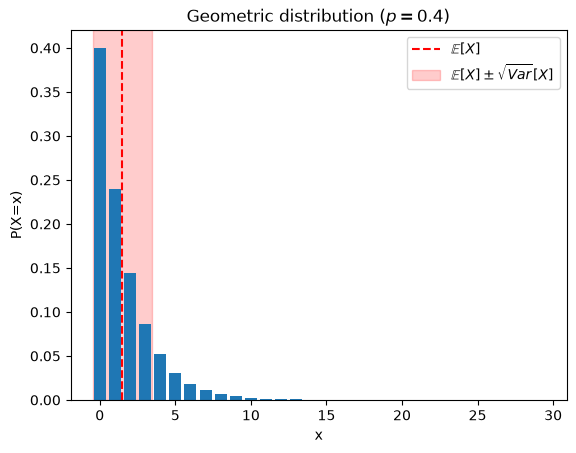

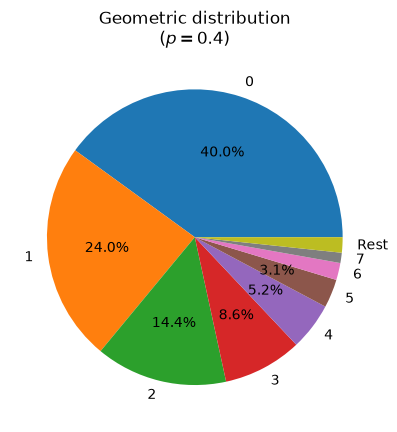

In [188]:
from matplotlib import pyplot as plt
from math import sqrt

p=0.4

def geometric_distribution(p=0.5):
    def f(x):
        x = int(x)
        if x >= 0:
            return p * (1-p)**x
        return 0
    return f

x_range = range(0,30)

mean = (1-p)/p
std = sqrt((1-p)/p**2)
mean_label = rf'$\mathbb{{E}}[X]$'
plt.axvline(x=mean,color='red',linestyle='--',label=mean_label)
std_label = rf'$\mathbb{{E}}[X]\pm\sqrt{{Var}}[X]$'
plt.axvspan(mean - std,mean + std,color='red',alpha=0.2,label=std_label)

f = geometric_distribution(p=p)
plt.bar(x_range,[f(x) for x in x_range])
plt.title('Geometric distribution '+rf'($p={p}$)')
plt.xlabel('x')
plt.ylabel('P(X=x)')
plt.legend()
plt.show()

# Pie Chart
resolution = 8
# How many slices are shown before the rest of the infinitely many is collapsed
x_range = range(0, resolution)
values = [f(x) for x in x_range]
values.append(1 - sum(values)) 
# Summarize the rest into one further category

labels = [str(x) for x in x_range]
labels.append('Rest')

def autopct_function(pct):
    return f'{pct:.1f}%' if pct >= 3 else ''

plt.pie(
    values,
    labels=labels,
    autopct=autopct_function,
    startangle=0
)

plt.title('Geometric distribution\n'+rf'($p={p}$)')
plt.show()




# Simulation

Simulating a geometric distribution with `NumPy` one has to be aware that `np.random.geometric(p)` yields the other convention for the geometric  distribution. To obtain ours we need to subtract `np.random.geometric(p)-1`. 

In [189]:
import numpy as np
p = 0.4
x = np.random.geometric(p)-1
print(x)

0


Via `NumPy` a sample can be obtained as follows

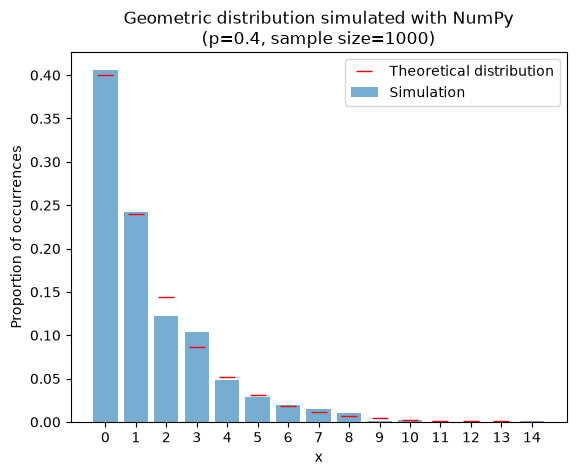

In [190]:
import numpy as np

p = 0.4
sample_size = 1000
samples = np.random.geometric(p, size=sample_size) - 1

def plot_simulation(samples, p, number_x_bins, title=""): 
    import matplotlib.pyplot as plt
    from scipy.stats import geom
    sample_size = len(samples)
    x_range = np.arange(0, number_x_bins)
    empirical = np.bincount(samples, minlength=len(x_range))[:len(x_range)] / sample_size
    plt.bar(x_range, empirical, label="Simulation", alpha=0.6)

    theoretical = geom.pmf(x_range + 1, p)
    plt.plot(x_range, theoretical, "r_", markersize=12, label="Theoretical distribution")

    plt.xlabel("x")
    plt.ylabel("Proportion of occurrences")
    plt.title(title)
    plt.xticks(x_range)
    plt.legend()
    plt.show()

title = f"Geometric distribution simulated with NumPy\n(p={p}, sample size={sample_size})"
plot_simulation(samples=samples, p=p, number_x_bins=15, title=title)

A sample can be obtained via `scipy` as follows. 

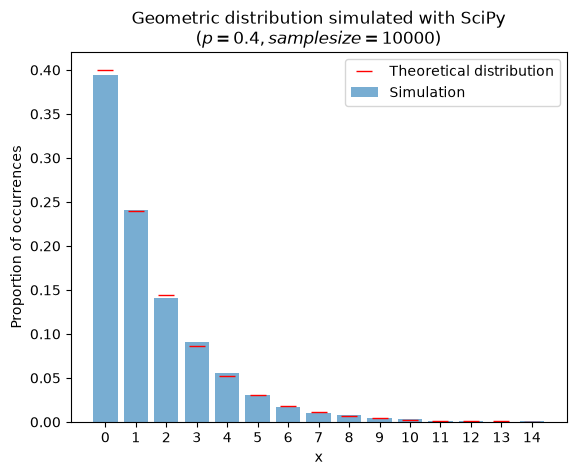

In [191]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import geom

p = 0.4
sample_size = 10_000
samples = geom.rvs(p, size=sample_size) - 1

title = "Geometric distribution simulated with SciPy\n"+rf"($p={p}, sample size = {sample_size}$)"
plot_simulation(samples=samples, p=p, number_x_bins=15, title = title)

Recall that the geometric distribution describes the number of failures before the first success in a sequence of independent Bernoulli trials, each with the same probability of success $p$. This is illustrated by the following simulation that only explores an implementation of the Bernoulli/Binomial distribution. 

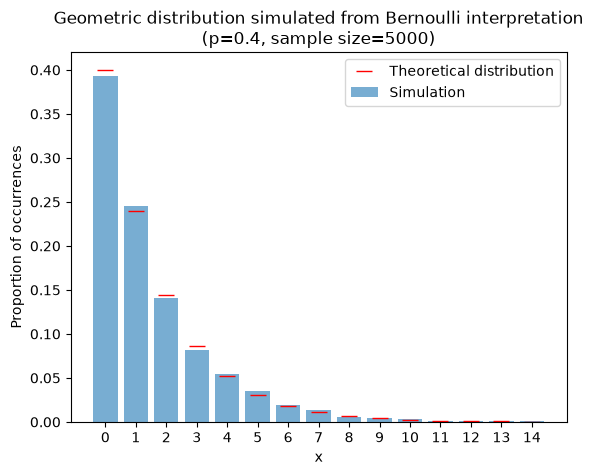

In [192]:
import numpy as np

p = 0.4

sample_size = 5000
samples = []
for k in range(sample_size):
    x=0
    while np.random.binomial(n=1, p=1-p):
        x+=1
    samples.append(x)

title = f"Geometric distribution simulated from Bernoulli interpretation\n(p={p}, sample size={sample_size})"
plot_simulation(samples=samples, p=p, number_x_bins=15, title = title)
